In [ ]:
from google.colab import files

uploaded = files.upload()

Saving POWER_Point_Daily_20250101_20251231_005d15S_119d43E_UTC (1).csv.xlsx to POWER_Point_Daily_20250101_20251231_005d15S_119d43E_UTC (1).csv (1).xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
nama_file = glob.glob ("Makasar.csv")[0]
# File NASA POWER biasanya memiliki metadata pada beberapa baris awal.
# Ubah angka skiprows jika judul kolom belum terbaca dengan benar.
df = pd.read_csv(nama_file, skiprows=15)
print(df.head())
print(df.columns)

IndexError: list index out of range

In [ ]:
# Membuat kolom tanggal
df["DATE"] = pd.to_datetime(
 dict(year=df["YEAR"], month=df["MO"], day=df["DY"])
)
df = df.set_index("DATE")
df.head()

NameError: name 'df' is not defined

In [ ]:
# Membersihkan data
# NASA POWER terkadang menggunakan nilai negatif tertentu untuk menandai data yang tidak tersedia.
kolom = [
 "ALLSKY_SFC_SW_DWN",
 "CLRSKY_SFC_SW_DWN",
 "T2M",
 "RH2M",
 "WS10M",
 "PRECTOTCORR"
]
for k in kolom:
 df[k] = pd.to_numeric(df[k], errors="coerce")
 df.loc[df[k] < -90, k] = np.nan
df = df.dropna(subset=["ALLSKY_SFC_SW_DWN", "T2M"])

NameError: name 'df' is not defined

In [ ]:
# Statistik dasar
statistik = df[kolom].describe().T
print(statistik)

                   count       mean        std      min      25%      50%  \
ALLSKY_SFC_SW_DWN  365.0   5.229407   1.082908   1.4724   4.6207   5.3321   
CLRSKY_SFC_SW_DWN  365.0   6.748815   0.658297   5.3422   6.1716   7.0135   
T2M                365.0  25.382521   0.875976  22.4900  24.8100  25.5500   
RH2M               365.0  85.816603   2.978668  75.8800  83.9000  85.8900   
WS10M              365.0   2.259589   0.788748   0.5600   1.6900   2.2100   
PRECTOTCORR        365.0   6.334849  10.555966   0.0100   0.4900   2.0700   

                       75%      max  
ALLSKY_SFC_SW_DWN   5.9995   7.3781  
CLRSKY_SFC_SW_DWN   7.2958   7.6306  
T2M                26.0500  27.0700  
RH2M               87.7100  93.2200  
WS10M               2.8200   4.1600  
PRECTOTCORR         7.3100  71.9100  


In [ ]:
# 6. Menghitung indeks kejernihan
df["Kc"] = (
 df["ALLSKY_SFC_SW_DWN"] /
 df["CLRSKY_SFC_SW_DWN"]
)
df["Kc"] = df["Kc"].clip(lower=0, upper=1.2)
print(df[[
 "ALLSKY_SFC_SW_DWN",
 "CLRSKY_SFC_SW_DWN",
 "Kc"
]].head())

            ALLSKY_SFC_SW_DWN  CLRSKY_SFC_SW_DWN        Kc
DATE                                                      
2025-01-01             2.4382             7.2197  0.337715
2025-01-02             3.2558             7.2430  0.449510
2025-01-03             3.9113             7.2161  0.542024
2025-01-04             3.9679             7.1561  0.554478
2025-01-05             4.4354             7.1503  0.620310


In [ ]:
# 7. Simulasi PLTS 1 kWp
kapasitas_kwp = 1.0
performance_ratio = 0.80
noct = 45
gamma = -0.004
G_puncak = 800

# Estimasi temperatur sel
df["T_cell"] = (
 df["T2M"] +
 ((noct - 20) / 800) * G_puncak
)
# Faktor koreksi temperatur
df["f_temp"] = 1 + gamma * (df["T_cell"] - 25)
# Energi tanpa koreksi temperatur
df["E_tanpa_koreksi_kWh"] = (
 df["ALLSKY_SFC_SW_DWN"] *
 kapasitas_kwp *
 performance_ratio
)
# Energi dengan koreksi temperatur
df["E_final_kWh"] = (
 df["ALLSKY_SFC_SW_DWN"] *
 kapasitas_kwp *
 performance_ratio *
 df["f_temp"]
)
print(df[[
 "ALLSKY_SFC_SW_DWN",
 "T2M",
 "T_cell",
 "E_final_kWh"
]].head())


            ALLSKY_SFC_SW_DWN    T2M  T_cell  E_final_kWh
DATE                                                     
2025-01-01             2.4382  24.49   49.49     1.759483
2025-01-02             3.2558  24.69   49.69     2.347406
2025-01-03             3.9113  25.10   50.10     2.814884
2025-01-04             3.9679  24.95   49.95     2.857523
2025-01-05             4.4354  25.57   50.57     3.185398


In [ ]:
# Visualisasi

In [ ]:
# 1 Grafik Radiasi Harian
plt.figure(figsize=(14, 5))
plt.plot(
 df.index,
 df["ALLSKY_SFC_SW_DWN"],
 color="orange",
 linewidth=1
)
plt.title("Radiasi Surya Harian")
plt.xlabel("Tanggal")
plt.ylabel("Radiasi (kWh/m²/hari)")
plt.grid(True, alpha=0.3)
plt.show()


NameError: name 'df' is not defined

<Figure size 1400x500 with 0 Axes>

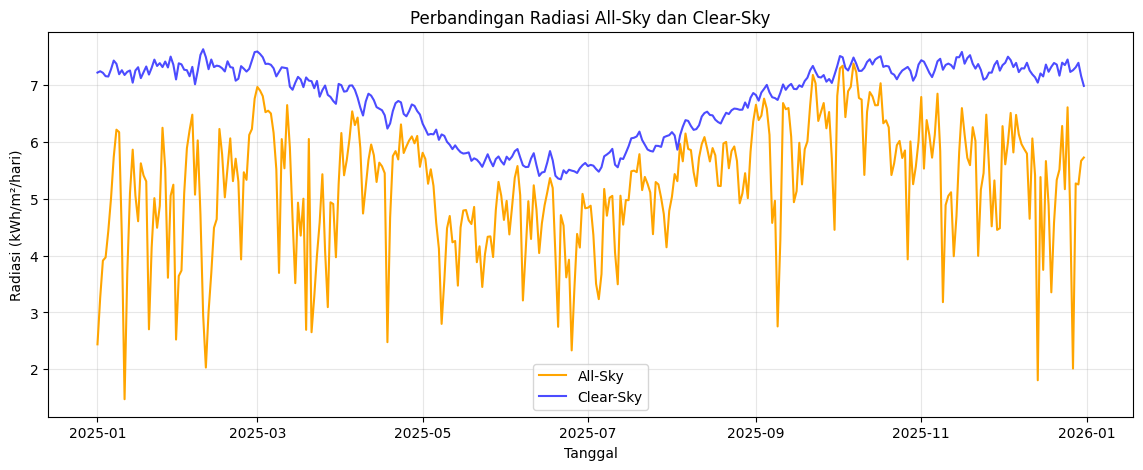

In [ ]:
# 2 Perbandingan radiasi aktual dan langit cerah
plt.figure(figsize=(14, 5))
plt.plot(
 df.index,
 df["ALLSKY_SFC_SW_DWN"],
 label="All-Sky",
 color="orange"
)
plt.plot(
 df.index,
 df["CLRSKY_SFC_SW_DWN"],
 label="Clear-Sky",
 color="blue",
 alpha=0.7
)
plt.title("Perbandingan Radiasi All-Sky dan Clear-Sky")
plt.xlabel("Tanggal")
plt.ylabel("Radiasi (kWh/m²/hari)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

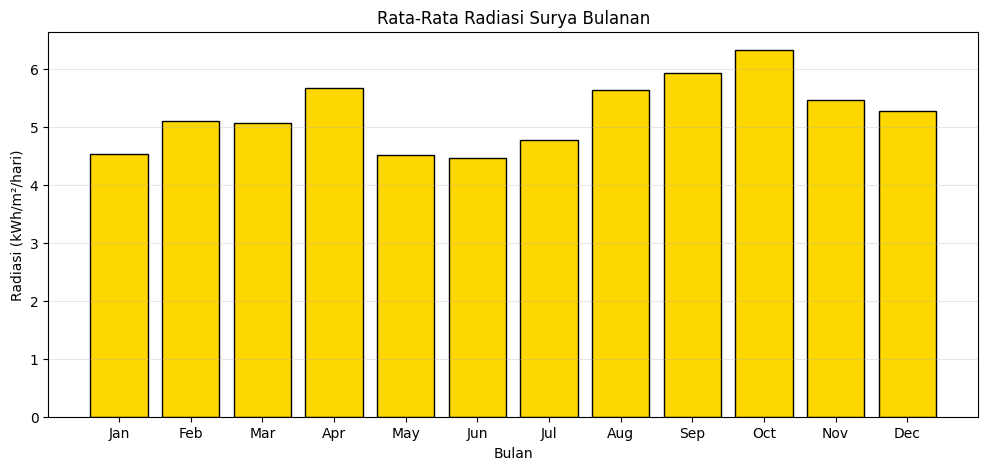

In [ ]:
# 3. Radiasi bulanan
bulanan = df.resample("ME").agg({
 "ALLSKY_SFC_SW_DWN": "mean",
 "T2M": "mean",
 "RH2M": "mean",
 "PRECTOTCORR": "sum",
 "E_final_kWh": "sum"
})
bulanan.index = bulanan.index.strftime("%b")
plt.figure(figsize=(12, 5))
plt.bar(
 bulanan.index,
 bulanan["ALLSKY_SFC_SW_DWN"],
 color="gold",
 edgecolor="black"
)
plt.title("Rata-Rata Radiasi Surya Bulanan")
plt.xlabel("Bulan")
plt.ylabel("Radiasi (kWh/m²/hari)")
plt.grid(axis="y", alpha=0.3)
plt.show()

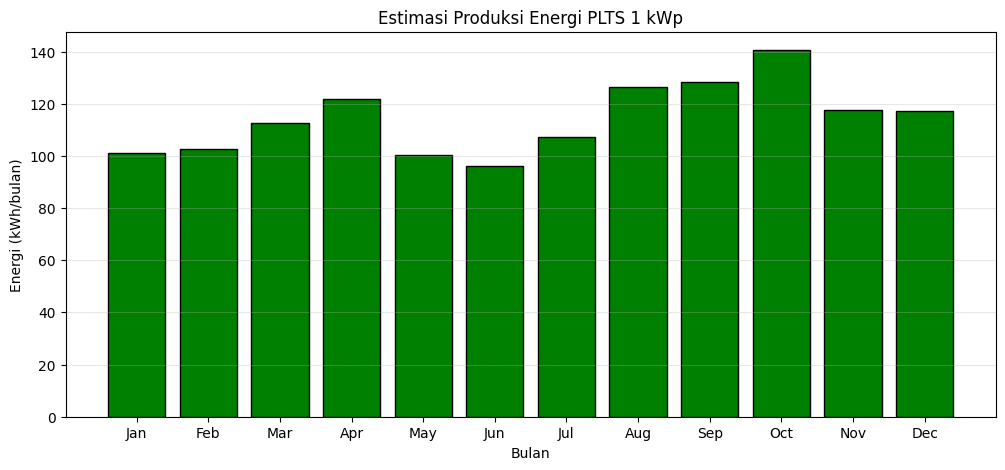

Produksi energi tahunan = 1371.71 kWh


In [ ]:
# 4. Estimasi energi PLTS bulanan
plt.figure(figsize=(12, 5))
plt.bar(
 bulanan.index,
 bulanan["E_final_kWh"],
 color="green",
 edgecolor="black"
)
plt.title("Estimasi Produksi Energi PLTS 1 kWp")
plt.xlabel("Bulan")
plt.ylabel("Energi (kWh/bulan)")
plt.grid(axis="y", alpha=0.3)
plt.show()
energi_tahunan = df["E_final_kWh"].sum()
print(f"Produksi energi tahunan = {energi_tahunan:.2f} kWh")

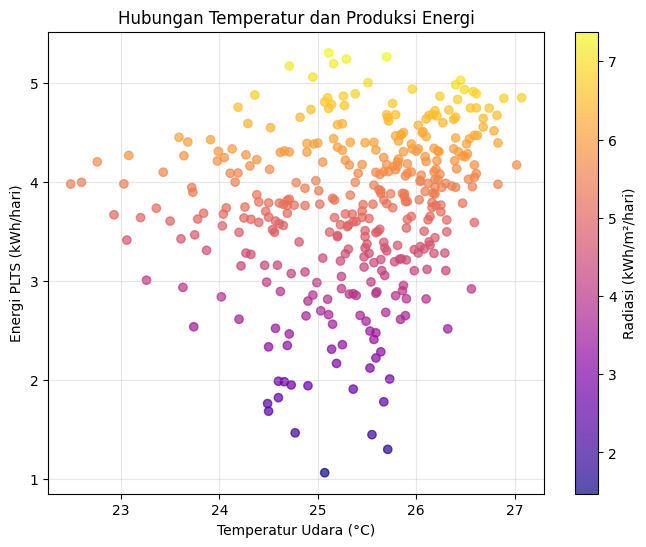

In [ ]:
# 5. Hubungan temperatur dan energi
plt.figure(figsize=(8, 6))
plt.scatter(
 df["T2M"],
 df["E_final_kWh"],
 c=df["ALLSKY_SFC_SW_DWN"],
 cmap="plasma",
 alpha=0.7
)
plt.colorbar(label="Radiasi (kWh/m²/hari)")
plt.title("Hubungan Temperatur dan Produksi Energi")
plt.xlabel("Temperatur Udara (°C)")
plt.ylabel("Energi PLTS (kWh/hari)")
plt.grid(True, alpha=0.3)
plt.show()

                   ALLSKY_SFC_SW_DWN    T2M   RH2M  WS10M  PRECTOTCORR  \
ALLSKY_SFC_SW_DWN              1.000  0.217 -0.531 -0.133       -0.321   
T2M                            0.217  1.000  0.054 -0.594        0.139   
RH2M                          -0.531  0.054  1.000  0.050        0.412   
WS10M                         -0.133 -0.594  0.050  1.000       -0.143   
PRECTOTCORR                   -0.321  0.139  0.412 -0.143        1.000   
E_final_kWh                    1.000  0.198 -0.535 -0.122       -0.325   

                   E_final_kWh  
ALLSKY_SFC_SW_DWN        1.000  
T2M                      0.198  
RH2M                    -0.535  
WS10M                   -0.122  
PRECTOTCORR             -0.325  
E_final_kWh              1.000  


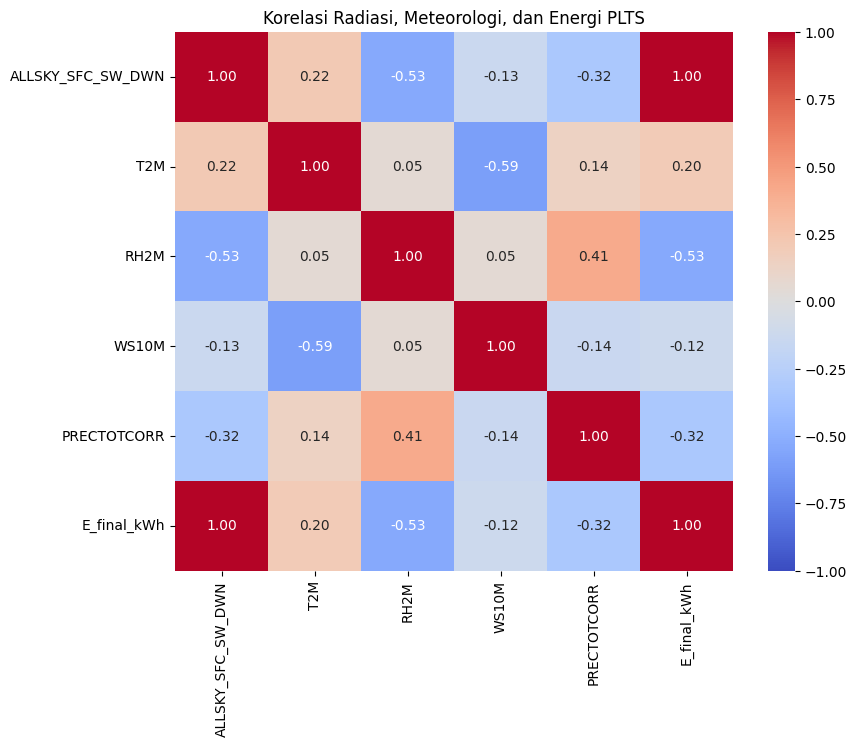

In [ ]:
# 6. Korelasi parameter meteorologi
parameter = [
 "ALLSKY_SFC_SW_DWN",
 "T2M",
 "RH2M",
 "WS10M",
 "PRECTOTCORR",
 "E_final_kWh"
]
korelasi = df[parameter].corr()
print(korelasi.round(3))
# Visualisasi matriks korelasi:
import seaborn as sns
plt.figure(figsize=(9, 7))
sns.heatmap(
 korelasi,
 annot=True,
 cmap="coolwarm",
 vmin=-1,
 vmax=1,
 fmt=".2f"
)
plt.title("Korelasi Radiasi, Meteorologi, dan Energi PLTS")
plt.show()

A_PR_075    1285.979785
B_PR_080    1371.711771
C_PR_085    1457.443757
Name: Energi_Tahunan_kWh, dtype: float64


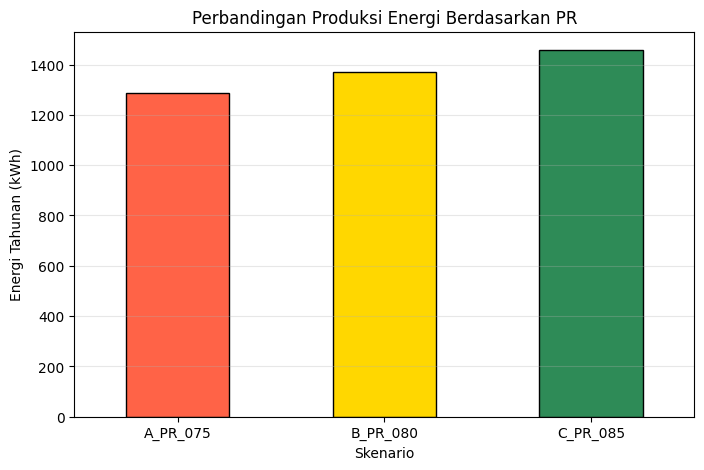

In [ ]:
skenario = {
 "A_PR_075": 0.75,
 "B_PR_080": 0.80,
 "C_PR_085": 0.85
}
hasil_skenario = {}
for nama, pr in skenario.items():
 energi = (
 df["ALLSKY_SFC_SW_DWN"] *
 kapasitas_kwp *
 pr *
 df["f_temp"]
 )
 hasil_skenario[nama] = energi.sum()
hasil_skenario = pd.Series(
 hasil_skenario,
 name="Energi_Tahunan_kWh"
)
print(hasil_skenario)
# Grafik perbandingan:
plt.figure(figsize=(8, 5))
hasil_skenario.plot(
 kind="bar",
 color=["tomato", "gold", "seagreen"],
 edgecolor="black"
)
plt.title("Perbandingan Produksi Energi Berdasarkan PR")
plt.xlabel("Skenario")
plt.ylabel("Energi Tahunan (kWh)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [ ]:
hari_tertinggi = df.loc[df["ALLSKY_SFC_SW_DWN"].idxmax()]
hari_terendah = df.loc[df["ALLSKY_SFC_SW_DWN"].idxmin()]
perbandingan = pd.DataFrame({
 "Hari Radiasi Tertinggi": hari_tertinggi,
 "Hari Radiasi Terendah": hari_terendah
})
print(perbandingan.loc[[
 "ALLSKY_SFC_SW_DWN",
 "CLRSKY_SFC_SW_DWN",
 "T2M",
 "RH2M",
 "WS10M",
 "PRECTOTCORR",
 "Kc",
 "E_final_kWh"
]])


                   Hari Radiasi Tertinggi  Hari Radiasi Terendah
ALLSKY_SFC_SW_DWN                7.378100               1.472400
CLRSKY_SFC_SW_DWN                7.484400               7.177400
T2M                             25.110000              25.070000
RH2M                            81.190000              89.610000
WS10M                            2.220000               2.340000
PRECTOTCORR                      0.220000              15.520000
Kc                               0.985797               0.205144
E_final_kWh                      5.309635               1.059798
